# 指数の時系列特性（市場全体・サイズ別・セクター別）

ファクター（クロスセクション）から一度離れて、インド株の**指数そのもの**が時系列でどう動くかを確認する。
目的は「時系列の性質（自己相関、トレンド、ボラの持続、季節性、オーバーナイト / 日中、為替）のうち、
クロスセクショナルなファクターやポートフォリオ運用に組み込めるものはあるか」を洗い出すこと。

**仮説 / 予測**（各セクションの冒頭にも書く）

1. **自己相関**: 新興市場では非同期取引と情報伝播の遅れで、指数の短期（日次・週次）の自己相関は正。等ウェイト・小型ほど強く、市場の成熟とともに弱まる。
2. **時系列モメンタム**: 指数レベルでも過去 3〜12 か月のリターンが翌月を予測する（Moskowitz–Ooi–Pedersen）。セクターでも同じ。
3. **ボラティリティ**: ボラは持続し（クラスタリング）、下落の後に上がる（レバレッジ効果）。ボラ管理（前月の実現分散の逆数でスケール）はシャープを上げる（Moreira–Muir）。
4. **季節性**: 3 月の会計年度末に損失銘柄の節税売り（小型・負け組）、4 月に反発。月替わり・祝日前は高い。F&O 満期の周辺は需給で歪む。
5. **オーバーナイト / 日中**: 米国のように「リターンはオーバーナイトで稼ぎ、日中は小さい（または負）」形がインドでも出るか。サイズで違うか。
6. **為替**: INR 安（USD/INR 上昇）は FPI の売りと同時に起き、株価と負の同時相関。翌月への予測力は弱い。

**設計 / 規約**

- データ: `scripts/build_market_panel.py` の共有パネル（`data/market_panel/`）。
  日次指数は**価格リターン**（配当なし）、月次指数は `drtn`（**配当込み**）。月末 $t$ のユニバースが月 $t+1$ の構成。
  CW = 前月末の時価総額で始め月中は買い持ち、EW = 等ウェイト。サイズ区分は MSCI の size（1 = 大型、2 = 中型、3 = 小型）。
- 主サンプル: 2008-01〜2026-07（日次 4,588 日、月次 223 か月）。シグナルの形成には 2007 年以前の大型株の履歴も使う。
- 検定: t 値は Newey–West（ラグは $\lfloor 4 (n/100)^{2/9} \rfloor$）。IS = 2008〜2017、OOS = 2018〜。
  季節性は多くの検定を並べるので、|t| > 2 でも単独では「候補」とし、IS / OOS の両方で同符号かを重視する。
- 無リスク金利のデータは無いので、シャープは**総リターン / ボラ**（現金 = 0%）。インドの短期金利は 4〜8% なので、
  現金を持つ戦略（ロング / フラット）には不利側の比較になる。

In [1]:
import sys
from pathlib import Path

import japanize_matplotlib  # noqa: F401  日本語ラベル用
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("../../scripts").resolve()))
from build_market_panel import SECTOR_NAMES, load_panel

pd.set_option("display.width", 260)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

START, END = "2008-01-01", "2026-07-31"
IS_END = "2017-12-31"
panel = load_panel(
    "../../data/market_panel", fields=("ret", "ret_on", "ret_id", "high", "low")
)
di_full = panel.daily_index.loc[:END]
mi_full = panel.monthly_index.loc[:END]
di = di_full.loc[START:END].copy()
mi = mi_full.loc[START:END].copy()
di["ew_cw"] = di["ew_imi"] - di["cw_imi"]
mi["ew_cw"] = mi["ew_imi"] - mi["cw_imi"]
SECTORS = [f"sec_{n}" for n in SECTOR_NAMES.values()]
MAIN = {
    "cw_imi": "CW IMI",
    "ew_imi": "EW IMI",
    "cw_large": "CW 大型",
    "ew_small": "EW 小型",
}
print(f"日次 {len(di)} 日, 月次 {len(mi)} か月")


def nw_ols(y, X, lags=None):
    # OLS と Newey–West の t 値。戻り値: 係数, t 値, R², n
    y = np.asarray(y, dtype=float)
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X[:, None]
    ok = np.isfinite(y) & np.isfinite(X).all(axis=1)
    y, X = y[ok], X[ok]
    n = len(y)
    if lags is None:
        lags = int(np.floor(4 * (n / 100) ** (2 / 9)))
    if n <= X.shape[1] or np.linalg.matrix_rank(X) < X.shape[1]:
        nan = np.full(X.shape[1], np.nan)
        return nan, nan, np.nan, n
    xtx_inv = np.linalg.inv(X.T @ X)
    b = xtx_inv @ X.T @ y
    e = y - X @ b
    xe = X * e[:, None]
    s = xe.T @ xe
    for lag in range(1, lags + 1):
        g = xe[lag:].T @ xe[:-lag]
        s += (1 - lag / (lags + 1)) * (g + g.T)
    se = np.sqrt(np.diag(xtx_inv @ s @ xtx_inv))
    r2 = 1 - e.var() / y.var()
    return b, b / se, r2, n


def with_const(*cols):
    return np.column_stack(
        [np.ones(len(cols[0]))] + [np.asarray(c, dtype=float) for c in cols]
    )


def nw_mean(x, lags=None):
    x = pd.Series(x).dropna()
    b, t, _, n = nw_ols(x.to_numpy(), np.ones((len(x), 1)), lags)
    return b[0], t[0]


def dummy_t(y, d):
    # y を「d の日 / それ以外」で比べた差と NW t 値
    y = pd.Series(y)
    d = d if isinstance(d, pd.Series) else pd.Series(np.asarray(d), index=y.index)
    df = pd.concat([y, d.astype(float)], axis=1).dropna()
    b, t, _, n = nw_ols(df.iloc[:, 0], with_const(df.iloc[:, 1]))
    return b[1], t[1], int(df.iloc[:, 1].sum())


def acf_nw(x, max_lag):
    x = pd.Series(x).dropna()
    rows = []
    for k in range(1, max_lag + 1):
        y = x.iloc[k:].to_numpy()
        z = x.shift(k).iloc[k:].to_numpy()
        b, t, _, _ = nw_ols(y, with_const(z))
        rows.append(
            {
                "lag": k,
                "rho": np.corrcoef(y, z)[0, 1],
                "se": abs(b[1] / t[1]),
                "t": t[1],
            }
        )
    return pd.DataFrame(rows).set_index("lag")


def sharpe(x, periods=12):
    x = pd.Series(x).dropna()
    return x.mean() / x.std() * np.sqrt(periods)


def split(s):
    if not isinstance(s, (pd.Series, pd.DataFrame)):
        s = pd.Series(s)
    return s.loc[:IS_END], s.loc[pd.Timestamp(IS_END) + pd.Timedelta(days=1) :]

日次 4588 日, 月次 223 か月


## 1. 自己相関と分散比

**仮説**: 日次・週次の指数リターンは正の自己相関を持つ（非同期取引・遅い情報伝播）。EW と小型ほど強い。市場の成熟とともに弱まる。

1. 日次・週次・月次のラグ 1〜4 の自己相関（$r_t$ を $r_{t-k}$ に回帰した NW t 値）
2. 日次のラグ 1〜10（誤差棒は ±1.96 NW 標準誤差）
3. セクター別のラグ 1
4. 2 年（504 営業日）ローリングのラグ 1 自己相関
5. Lo–MacKinlay の分散比 $VR(q)$（不均一分散に頑健な $z^*$）。$VR > 1$ は正の自己相関（トレンド）、$< 1$ は平均回帰

In [2]:
wk = (1 + di).resample("W-FRI").prod(min_count=1) - 1
freqs = {"日次": di, "週次": wk, "月次": mi}
rows = {}
for fname, df in freqs.items():
    for c, lab in {**MAIN, "ew_cw": "EW−CW"}.items():
        a = acf_nw(df[c], 4)
        row = {f"ρ{k}": a.loc[k, "rho"] for k in range(1, 5)}
        row.update({f"t{k}": a.loc[k, "t"] for k in range(1, 5)})
        rows[(fname, lab)] = row
acf_tbl = pd.DataFrame(rows).T
print("自己相関（ρ）と NW t 値、2008-01〜2026-07")
display(acf_tbl.round(3))

自己相関（ρ）と NW t 値、2008-01〜2026-07


ρ1     ρ2     ρ3     ρ4     t1     t2     t3     t4
日次 CW IMI  0.051  0.016 -0.001 -0.030  1.965  0.678 -0.043 -1.069
   EW IMI  0.159  0.074  0.055  0.002  7.662  2.994  2.391  0.072
   CW 大型   0.026 -0.002 -0.018 -0.034  0.935 -0.092 -0.763 -1.094
   EW 小型   0.186  0.086  0.065  0.007  9.165  3.378  2.675  0.329
   EW−CW   0.150 -0.008 -0.011 -0.012  6.891 -0.295 -0.549 -0.520
週次 CW IMI  0.049  0.140 -0.040  0.051  0.915  2.552 -0.888  1.003
   EW IMI  0.137  0.166 -0.021  0.040  2.832  3.177 -0.556  0.997
   CW 大型   0.006  0.121 -0.047  0.046  0.113  2.215 -0.961  0.873
   EW 小型   0.145  0.171 -0.014  0.036  3.028  3.327 -0.354  0.941
   EW−CW  -0.050  0.087 -0.034  0.016 -1.524  1.931 -0.654  0.460
月次 CW IMI  0.089 -0.028  0.094  0.114  0.893 -0.352  1.547  1.288
   EW IMI  0.137 -0.021  0.069  0.119  1.675 -0.272  1.204  1.578
   CW 大型   0.047 -0.031  0.101  0.092  0.466 -0.392  1.604  1.015
   EW 小型   0.140 -0.010  0.064  0.116  1.765 -0.144  1.073  1.591
   EW−CW   0.004 -0.006  0.075 -0.048  0.070 -0.113  1.213 -0.675

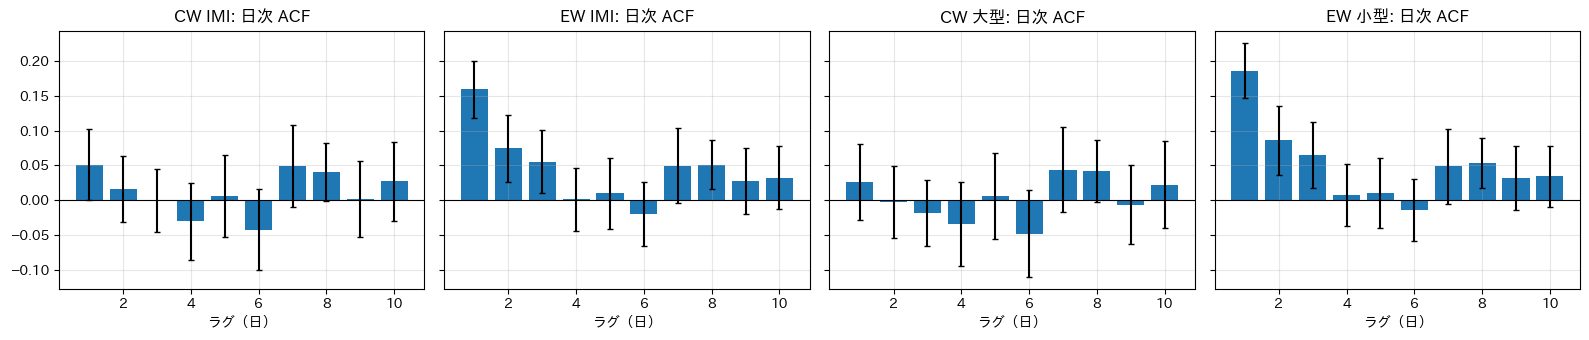

セクター（CW）のラグ 1 自己相関


,日次 ρ1,日次 t,週次 ρ1,週次 t
Energy,0.028,0.925,-0.041,-0.852
Materials,0.071,2.673,0.078,1.621
Industrials,0.125,5.808,0.097,1.836
ConsDisc,0.090,4.118,0.066,1.414
ConsStap,0.009,0.319,0.008,0.268
HealthCare,0.059,2.083,0.049,1.230
Financials,0.073,3.163,-0.001,-0.017
IT,0.012,0.507,-0.003,-0.067
CommSvc,0.004,0.135,-0.008,-0.199
Utilities,0.046,1.628,0.068,1.343


In [3]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, (c, lab) in zip(axes, MAIN.items()):
    a = acf_nw(di[c], 10)
    ax.bar(a.index, a["rho"], color="C0")
    ax.errorbar(
        a.index, a["rho"], yerr=1.96 * a["se"], fmt="none", ecolor="k", capsize=2
    )
    ax.axhline(0, color="k", linewidth=0.8)
    ax.set_title(f"{lab}: 日次 ACF")
    ax.set_xlabel("ラグ（日）")
plt.tight_layout()
plt.show()

rows = {}
for s in SECTORS:
    d1 = acf_nw(di[s], 1)
    w1 = acf_nw(wk[s], 1)
    rows[s.replace("sec_", "")] = {
        "日次 ρ1": d1.loc[1, "rho"],
        "日次 t": d1.loc[1, "t"],
        "週次 ρ1": w1.loc[1, "rho"],
        "週次 t": w1.loc[1, "t"],
    }
print("セクター（CW）のラグ 1 自己相関")
display(pd.DataFrame(rows).T.round(3))

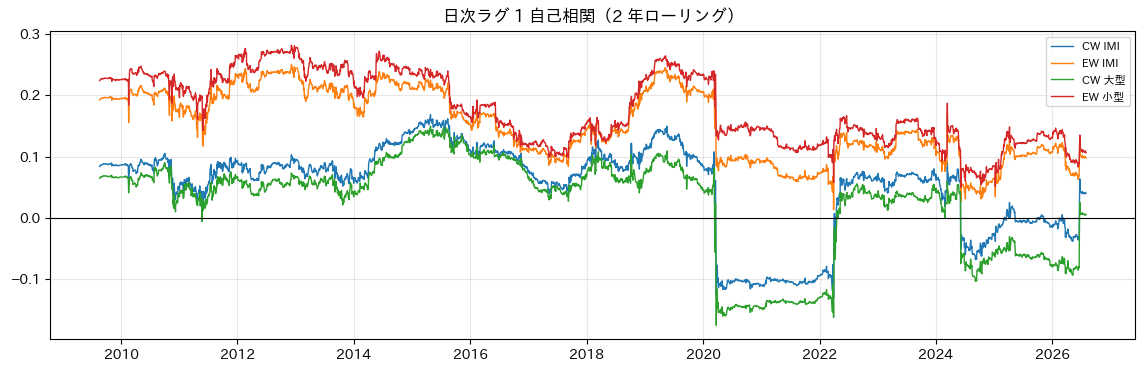

CW IMI: ρ1 IS 0.088（t 3.2） / OOS -0.026（t -0.6）
EW IMI: ρ1 IS 0.191（t 7.2） / OOS 0.102（t 3.4）
CW 大型: ρ1 IS 0.068（t 2.4） / OOS -0.065（t -1.4）
EW 小型: ρ1 IS 0.218（t 8.0） / OOS 0.131（t 4.8）


In [4]:
fig, ax = plt.subplots(figsize=(14, 4))
for c, lab in MAIN.items():
    x = di[c]
    roll = x.rolling(504, min_periods=400).corr(x.shift(1))
    ax.plot(roll.index, roll, label=lab, linewidth=1)
ax.axhline(0, color="k", linewidth=0.8)
ax.set_title("日次ラグ 1 自己相関（2 年ローリング）")
ax.legend(fontsize=8)
plt.show()

for c, lab in MAIN.items():
    a, b = split(di[c])
    print(
        f"{lab}: ρ1 IS {acf_nw(a, 1).loc[1, 'rho']:.3f}（t {acf_nw(a, 1).loc[1, 't']:.1f}）"
        f" / OOS {acf_nw(b, 1).loc[1, 'rho']:.3f}（t {acf_nw(b, 1).loc[1, 't']:.1f}）"
    )

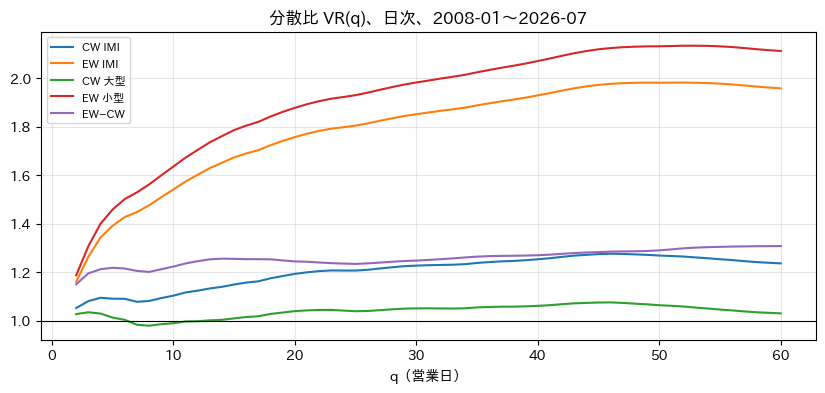

,VR(5),VR(20),VR(60),z(5),z(20),z(60)
CW IMI,1.090,1.193,1.236,1.400,1.350,1.033
EW IMI,1.391,1.757,1.958,6.314,6.004,4.837
CW 大型,1.012,1.039,1.030,0.185,0.260,0.123
EW 小型,1.458,1.877,2.112,7.349,7.079,5.752
EW−CW,1.218,1.244,1.307,3.186,1.895,1.537


In [5]:
def variance_ratio(r, q):
    # Lo–MacKinlay の分散比（重複 q 期間和）と不均一分散に頑健な z*
    r = pd.Series(r).dropna().to_numpy()
    n = len(r)
    mu = r.mean()
    s1 = ((r - mu) ** 2).sum() / (n - 1)
    rq = np.convolve(r, np.ones(q), "valid")
    m = q * (n - q + 1) * (1 - q / n)
    vr = ((rq - q * mu) ** 2).sum() / m / s1
    e2 = (r - mu) ** 2
    theta = sum(
        (2 * (q - j) / q) ** 2 * n * (e2[j:] * e2[:-j]).sum() / e2.sum() ** 2
        for j in range(1, q)
    )
    return vr, np.sqrt(n) * (vr - 1) / np.sqrt(theta)


qs = list(range(2, 61))
fig, ax = plt.subplots(figsize=(10, 4))
vr_rows = {}
for c, lab in {**MAIN, "ew_cw": "EW−CW"}.items():
    vals = [variance_ratio(di[c], q) for q in qs]
    ax.plot(qs, [v[0] for v in vals], label=lab)
    vr_rows[lab] = {f"VR({q})": variance_ratio(di[c], q)[0] for q in (5, 20, 60)} | {
        f"z({q})": variance_ratio(di[c], q)[1] for q in (5, 20, 60)
    }
ax.axhline(1, color="k", linewidth=0.8)
ax.set_xlabel("q（営業日）")
ax.set_title("分散比 VR(q)、日次、2008-01〜2026-07")
ax.legend(fontsize=8)
plt.show()
display(pd.DataFrame(vr_rows).T.round(3))

## 2. 時系列モメンタム（指数レベル）

**仮説**: 過去 $k$ か月（1, 3, 6, 12）の累積リターンが正なら翌月も正に傾く。セクターでも同じ。

- 月 $t$ 末までの $k$ か月の対数リターンの符号 $s_t$ で、月 $t+1$ の `drtn` 指数リターンを予測（$r_{t+1} = a + b\,s_t$、NW t）。
- 戦略: ロング / フラット（$s_t > 0$ で保有、それ以外は現金 0%）とロング / ショート（$s_t$ 倍）。買い持ちとシャープを比べる。
- セクター TSMOM: 11 セクターそれぞれ $s_t / \hat\sigma_t$（$\hat\sigma$ = 過去 36 か月の月次標準偏差）で持ち、グロスで正規化した合計。
  **絶対**（セクターリターンそのもの）と**相対**（セクター − CW IMI。業種モメンタムのクロスセクションに近い）に分ける。

In [6]:
TS_SERIES = {
    "cw_imi": "CW IMI",
    "cw_msci": "CW MSCI",
    "ew_imi": "EW IMI",
    "cw_large": "CW 大型",
    "cw_mid": "CW 中型",
    "cw_small": "CW 小型",
    "ew_small": "EW 小型",
}
KS = (1, 3, 6, 12)
logm = np.log1p(mi_full)


def tsmom_eval(r, k):
    sig = (
        np.log1p(r).rolling(k, min_periods=k).sum().shift(1)
    )  # 月 t 末までの k か月 → 月 t+1
    df = pd.DataFrame({"y": r, "s": np.sign(sig), "m": sig}).loc[START:END].dropna()
    b, t, _, _ = nw_ols(df["y"], with_const(df["s"]))
    out = {"b(%/月)": b[1] * 100, "t": t[1]}
    for name, part in zip(("IS", "OOS"), split(df)):
        bb, tt, _, _ = nw_ols(part["y"], with_const(part["s"]))
        out[f"t {name}"] = tt[1]
    lf = df["y"] * (df["s"] > 0)
    out["SR 買い持ち"] = sharpe(df["y"])
    out["SR L/F"] = sharpe(lf)
    out["SR L/S"] = sharpe(df["y"] * df["s"])
    out["保有率"] = (df["s"] > 0).mean()
    return out


rows = {}
for c, lab in TS_SERIES.items():
    for k in KS:
        rows[(lab, k)] = tsmom_eval(mi_full[c], k)
ts_tbl = pd.DataFrame(rows).T
print("指数の TSMOM（符号）: 月次、評価 2008-01〜2026-07")
display(ts_tbl.round(2))

指数の TSMOM（符号）: 月次、評価 2008-01〜2026-07


b(%/月)     t  t IS  t OOS  SR 買い持ち  SR L/F  SR L/S   保有率
CW IMI  1     0.14  0.41  0.04   0.58     0.50    0.50    0.19  0.62
        3     0.56  1.31  1.09   0.78     0.50    0.67    0.41  0.61
        6    -0.17 -0.32  1.13  -2.38     0.50    0.39    0.06  0.65
        12   -0.56 -0.77  0.07  -2.40     0.50    0.37    0.04  0.77
CW MSCI 1     0.05  0.14 -0.68   1.19     0.50    0.46    0.13  0.60
        3     0.53  1.29  1.57  -0.22     0.50    0.66    0.40  0.61
        6    -0.19 -0.37  0.94  -2.38     0.50    0.40    0.08  0.68
        12   -0.53 -0.74 -0.08  -2.26     0.50    0.37    0.06  0.78
EW IMI  1     0.43  1.00  0.62   0.88     0.44    0.47    0.24  0.57
        3     0.95  1.86  1.71   0.82     0.44    0.68    0.48  0.60
        6     0.18  0.31  0.95  -0.74     0.44    0.42    0.17  0.61
        12   -0.22 -0.34 -0.33  -0.14     0.44    0.39    0.03  0.63
CW 大型   1     0.07  0.21 -0.72   1.48     0.49    0.47    0.13  0.59
        3     0.55  1.38  1.50   0.09     0.49    0.67    0.43  0.62
        6    -0.13 -0.26  1.04  -2.47     0.49    0.41    0.11  0.69
        12   -0.60 -0.82 -0.23  -2.37     0.49    0.35    0.05  0.79
CW 中型   1    -0.01 -0.03 -0.60   0.89     0.50    0.42    0.10  0.61
        3     0.65  1.24  1.07   0.65     0.50    0.65    0.39  0.59
        6     0.02  0.04  0.67  -1.05     0.50    0.46    0.13  0.62
        12   -0.47 -0.80 -0.73  -0.32     0.50    0.34   -0.02  0.68
CW 小型   1     0.55  1.22  1.15   0.50     0.48    0.55    0.31  0.59
        3     0.97  1.86  1.64   0.92     0.48    0.72    0.50  0.60
        6     0.32  0.55  1.13  -0.51     0.48    0.49    0.25  0.63
        12   -0.19 -0.28  0.20  -0.80     0.62    0.55    0.09  0.64
EW 小型   1     0.51  1.11  1.14   0.32     0.43    0.48    0.26  0.57
        3     1.14  2.15  1.83   1.19     0.43    0.71    0.53  0.59
        6     0.29  0.45  1.04  -0.57     0.43    0.43    0.21  0.61
        12   -0.23 -0.35  0.08  -0.78     0.56    0.52    0.01  0.59

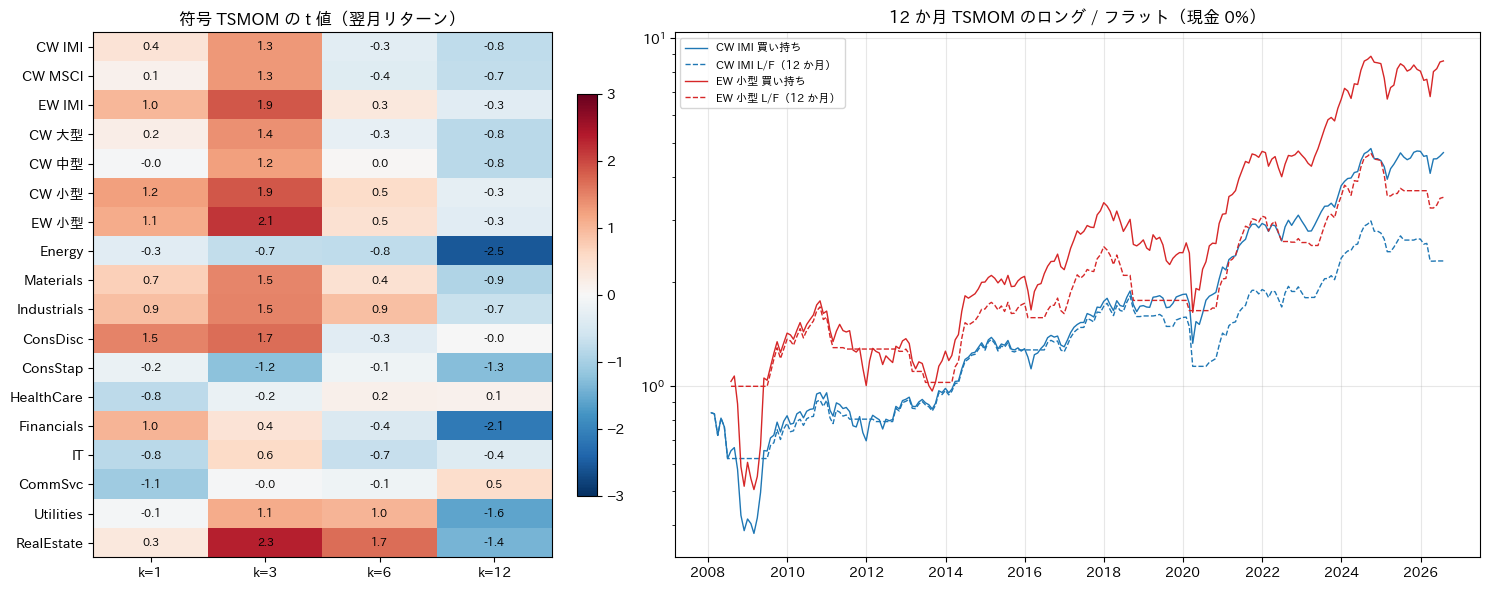

In [7]:
tmat = pd.DataFrame(
    {
        k: {
            lab: tsmom_eval(mi_full[c], k)["t"]
            for c, lab in {
                **TS_SERIES,
                **{s: s.replace("sec_", "") for s in SECTORS},
            }.items()
        }
        for k in KS
    }
)
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.6]})
im = axes[0].imshow(tmat.to_numpy(), cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
axes[0].set_xticks(range(len(KS)), [f"k={k}" for k in KS])
axes[0].set_yticks(range(len(tmat)), tmat.index)
for i in range(tmat.shape[0]):
    for j in range(tmat.shape[1]):
        axes[0].text(
            j, i, f"{tmat.iat[i, j]:.1f}", ha="center", va="center", fontsize=8
        )
axes[0].set_title("符号 TSMOM の t 値（翌月リターン）")
axes[0].grid(False)
plt.colorbar(im, ax=axes[0], fraction=0.04)

for c, col in (("cw_imi", "C0"), ("ew_small", "C3")):
    r = mi_full[c]
    sig = np.log1p(r).rolling(12, min_periods=12).sum().shift(1)
    df = pd.DataFrame({"y": r, "s": sig}).loc[START:END].dropna()
    axes[1].plot(
        (1 + df["y"]).cumprod(),
        color=col,
        linewidth=1,
        label=f"{TS_SERIES[c]} 買い持ち",
    )
    axes[1].plot(
        (1 + df["y"] * (df["s"] > 0)).cumprod(),
        color=col,
        linestyle="--",
        linewidth=1,
        label=f"{TS_SERIES[c]} L/F（12 か月）",
    )
axes[1].set_yscale("log")
axes[1].legend(fontsize=8)
axes[1].set_title("12 か月 TSMOM のロング / フラット（現金 0%）")
plt.tight_layout()
plt.show()

セクター TSMOM（逆ボラ加重、11 セクター）


年率      t     SR   t IS  t OOS  CW IMI との相関
絶対 1   0.021  0.584  0.123  0.293  0.687       -0.086
   3   0.054  1.477  0.352  1.023  1.130       -0.002
   6   0.043  1.030  0.268  1.842 -0.358        0.031
   12  0.006  0.145  0.039 -0.107  0.423        0.004
相対 1   0.012  0.959  0.215  0.787  0.562       -0.060
   3   0.012  1.072  0.198  0.647  0.936       -0.053
   6   0.010  0.751  0.165  0.838  0.209       -0.137
   12  0.013  0.793  0.193  0.218  1.260       -0.331

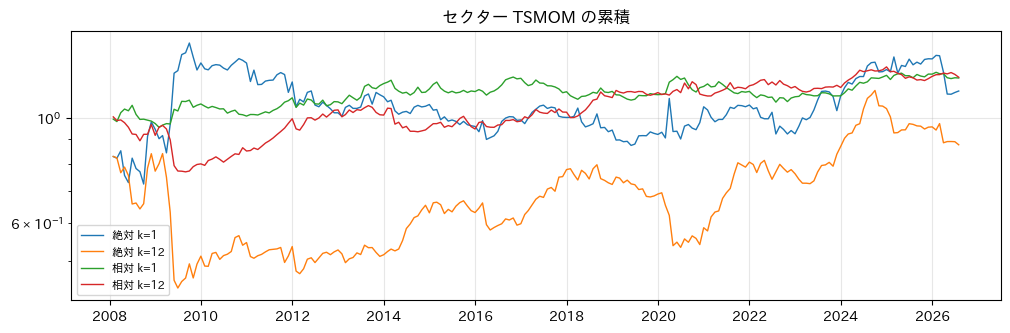

In [8]:
def sector_tsmom(k, relative):
    R = mi_full[SECTORS]
    if relative:
        R = R.sub(mi_full["cw_imi"], axis=0)
    sig = np.sign(R.rolling(k, min_periods=k).sum()).shift(1)
    vol = R.rolling(36, min_periods=24).std().shift(1)
    w = (1 / vol).where(sig.notna() & R.notna())
    w = w.div(w.sum(axis=1), axis=0)
    return (w * sig * R).sum(axis=1, min_count=1).loc[START:END].dropna()


rows = {}
sec_ports = {}
for rel in (False, True):
    for k in KS:
        p = sector_tsmom(k, rel)
        sec_ports[(rel, k)] = p
        m, t = nw_mean(p)
        a, b = split(p)
        rows[("相対" if rel else "絶対", k)] = {
            "年率": m * 12,
            "t": t,
            "SR": sharpe(p),
            "t IS": nw_mean(a)[1],
            "t OOS": nw_mean(b)[1],
            "CW IMI との相関": p.corr(mi["cw_imi"]),
        }
print("セクター TSMOM（逆ボラ加重、11 セクター）")
display(pd.DataFrame(rows).T.round(3))

fig, ax = plt.subplots(figsize=(12, 3.5))
for (rel, k), p in sec_ports.items():
    if k in (1, 12):
        ax.plot(
            (1 + p).cumprod(), label=f"{'相対' if rel else '絶対'} k={k}", linewidth=1
        )
ax.set_yscale("log")
ax.legend(fontsize=8)
ax.set_title("セクター TSMOM の累積")
plt.show()

## 3. ボラティリティ

**仮説**: ボラは持続する（|r| の自己相関が長く続く）。下落の後にボラが上がる（レバレッジ効果）。
ボラ管理は同じボラの買い持ちよりシャープが高い（Moreira–Muir）。ボラが高い月の翌月は期待リターンが高いとは限らない。

- 月次実現ボラ $RV_m = \sqrt{12 \sum_{d \in m} r_d^2}$（日次の価格指数から）。
- HAR: $\log RV_{m+1} = a + b_1 \log RV_m + b_3 \overline{\log RV}_{m-2..m} + b_{12} \overline{\log RV}_{m-11..m}$。OOS は 2013 年からの拡大窓。
- レンジボラ: 個別株の Parkinson 推定 $\sigma_P^2 = \ln(H/L)^2 / (4 \ln 2)$ の時価加重平均（**平均的な個別株のボラ**で、指数のボラではない）。
- ボラ管理: $f^\sigma_{t+1} = c\, f_{t+1} / RV_t^2$（または $/RV_t$）、$c$ は全期間でボラが等しくなるよう決める（事後のスケールだが、シャープと回帰アルファには影響しない）。

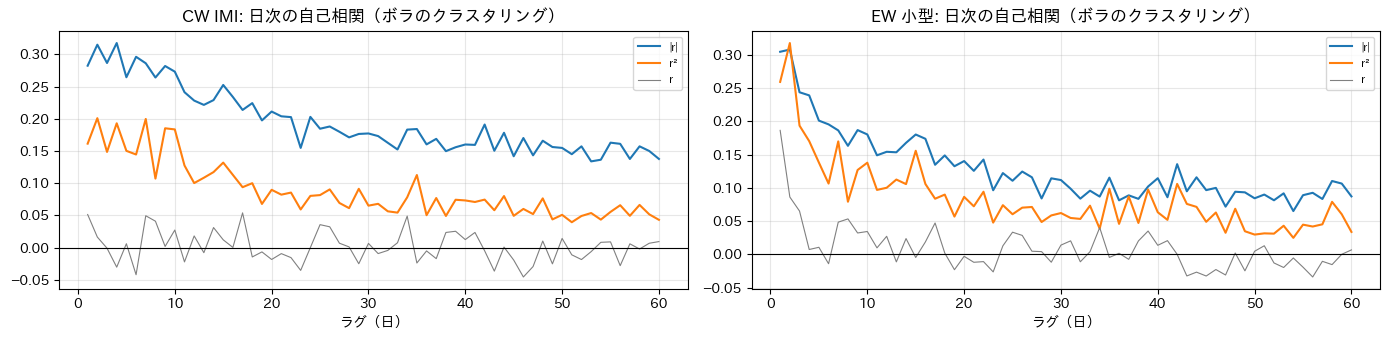

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
lags = range(1, 61)
for ax, c in zip(axes, ("cw_imi", "ew_small")):
    x = di[c]
    ax.plot(lags, [x.abs().autocorr(k) for k in lags], label="|r|")
    ax.plot(lags, [(x**2).autocorr(k) for k in lags], label="r²")
    ax.plot(lags, [x.autocorr(k) for k in lags], label="r", color="gray", linewidth=0.8)
    ax.axhline(0, color="k", linewidth=0.8)
    ax.set_title(f"{MAIN[c]}: 日次の自己相関（ボラのクラスタリング）")
    ax.set_xlabel("ラグ（日）")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


def monthly_rv(x):
    x = x.dropna()
    s = (x**2).groupby(x.index.to_period("M")).sum()
    s.index = s.index.to_timestamp(how="end").normalize()
    return np.sqrt(12 * s)


RV = pd.DataFrame(
    {
        c: monthly_rv(di_full[c])
        for c in ["cw_imi", "cw_msci", "ew_imi", "cw_large", "cw_small", "ew_small"]
    }
)

log 実現ボラ（CW IMI）の翌月予測


,R²,OOS R²,t(m1),t(m3),t(m12),t(pk),t(r)
AR(1),0.457,0.419,11.525,NaN,NaN,NaN,NaN
HAR,0.492,0.439,3.474,1.350,2.122,NaN,NaN
HAR + レンジ,0.530,0.467,0.565,0.728,1.420,3.83,NaN
AR(1) + r（レバレッジ）,0.466,0.425,10.053,NaN,NaN,NaN,-1.664


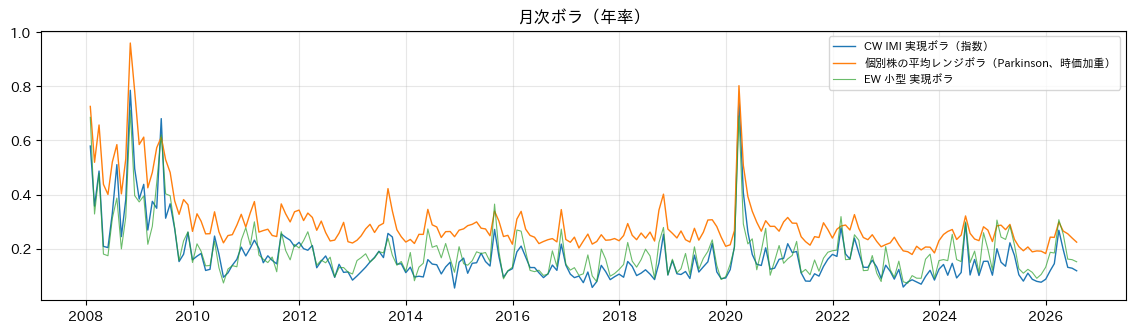

指数ボラ / 平均個別株ボラ の平均: 0.553


In [10]:
# 平均的な個別株の Parkinson レンジボラ（時価加重）
hi = panel.daily["high"].loc[START:END]
lo = panel.daily["low"].loc[START:END]
cap_d = panel.member_daily("cap").loc[START:END].reindex(columns=hi.columns)
pk = np.log(hi.where(hi > 0) / lo.where(lo > 0))
pk = pk.where((pk >= 0) & (pk < 1.0))
sig_p = np.sqrt(pk**2 / (4 * np.log(2)))
w = cap_d.where(sig_p.notna())
pk_d = (sig_p * w).sum(axis=1) / w.sum(axis=1)
PK = pk_d.groupby(pk_d.index.to_period("M")).mean() * np.sqrt(252)
PK.index = PK.index.to_timestamp(how="end").normalize()
del hi, lo, pk, sig_p, w

lrv = np.log(RV["cw_imi"])
har = (
    pd.DataFrame(
        {
            "y": lrv.shift(-1),
            "m1": lrv,
            "m3": lrv.rolling(3).mean(),
            "m12": lrv.rolling(12).mean(),
            "pk": np.log(PK).reindex(lrv.index),
            "r": mi_full["cw_imi"],
        }
    )
    .loc[START:END]
    .dropna()
)
specs = {
    "AR(1)": ["m1"],
    "HAR": ["m1", "m3", "m12"],
    "HAR + レンジ": ["m1", "m3", "m12", "pk"],
    "AR(1) + r（レバレッジ）": ["m1", "r"],
}
rows = {}
for name, xs in specs.items():
    b, t, r2, n = nw_ols(har["y"], with_const(*[har[x] for x in xs]))
    # 拡大窓の OOS R²（2013 年以降、過去平均に対して）
    pred, bench, real = [], [], []
    for i, d in enumerate(har.index):
        if d < pd.Timestamp("2013-01-31"):
            continue
        tr = har.iloc[:i]
        bb = np.linalg.lstsq(
            with_const(*[tr[x] for x in xs]), tr["y"].to_numpy(), rcond=None
        )[0]
        pred.append(bb @ np.r_[1.0, har.loc[d, xs].to_numpy(dtype=float)])
        bench.append(tr["y"].mean())
        real.append(har.loc[d, "y"])
    real, pred, bench = map(np.asarray, (real, pred, bench))
    rows[name] = {
        "R²": r2,
        "OOS R²": 1 - ((real - pred) ** 2).sum() / ((real - bench) ** 2).sum(),
    }
    rows[name].update({f"t({x})": tv for x, tv in zip(xs, t[1:])})
print("log 実現ボラ（CW IMI）の翌月予測")
display(pd.DataFrame(rows).T.round(3))

fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(RV["cw_imi"].loc[START:], label="CW IMI 実現ボラ（指数）", linewidth=1)
ax.plot(PK, label="個別株の平均レンジボラ（Parkinson、時価加重）", linewidth=1)
ax.plot(RV["ew_small"].loc[START:], label="EW 小型 実現ボラ", linewidth=0.8, alpha=0.7)
ax.set_title("月次ボラ（年率）")
ax.legend(fontsize=8)
plt.show()
print(
    "指数ボラ / 平均個別株ボラ の平均:", (RV["cw_imi"].loc[START:] / PK).mean().round(3)
)

CW IMI: corr(r_t, |r_(t+k)|) の k=1..5 平均 -0.109, k=-5..-1 平均 0.008
EW 小型: corr(r_t, |r_(t+k)|) の k=1..5 平均 -0.108, k=-5..-1 平均 0.029


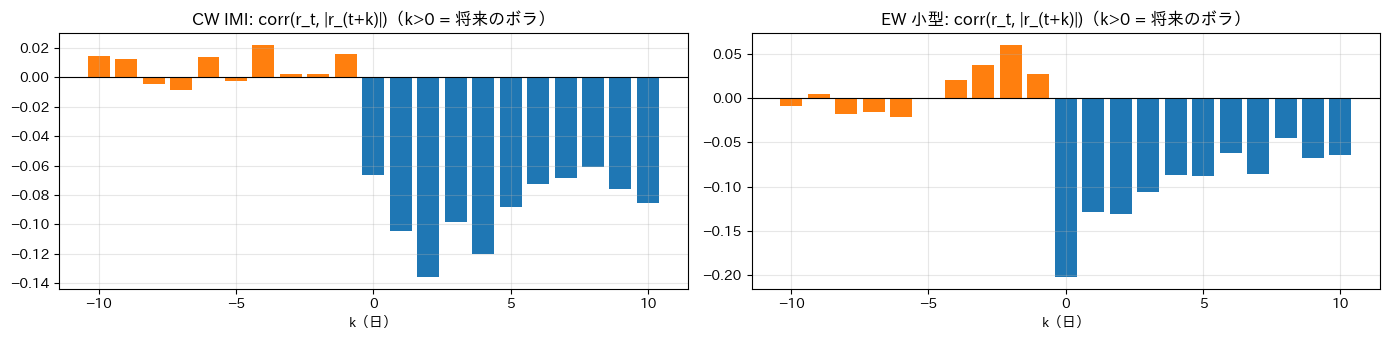

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
ks = range(-10, 11)
for ax, c in zip(axes, ("cw_imi", "ew_small")):
    x = di[c]
    cc = [x.corr(x.abs().shift(-k)) for k in ks]  # corr(r_t, |r_{t+k}|)
    ax.bar(list(ks), cc, color=["C1" if k < 0 else "C0" for k in ks])
    ax.axhline(0, color="k", linewidth=0.8)
    ax.set_title(f"{MAIN[c]}: corr(r_t, |r_(t+k)|)（k>0 = 将来のボラ）")
    ax.set_xlabel("k（日）")
    print(
        f"{MAIN[c]}: corr(r_t, |r_(t+k)|) の k=1..5 平均 {np.mean(cc[11:16]):.3f}, k=-5..-1 平均 {np.mean(cc[5:10]):.3f}"
    )
plt.tight_layout()
plt.show()

ボラ管理（前月の実現ボラでスケール、月次 drtn）


α 年率    α t      β  SR 買い持ち  SR 管理  α t IS  α t OOS  倍率 中央  倍率 最大
cw_imi   1/RV²  0.063  1.500  0.627    0.499  0.610   1.182    0.615  0.916  6.220
         1/RV   0.036  1.362  0.873    0.499  0.606   1.140    0.397  1.203  3.135
cw_msci  1/RV²  0.057  1.462  0.597    0.498  0.577   0.934    0.894  0.855  6.397
         1/RV   0.035  1.386  0.864    0.498  0.602   1.008    0.624  1.191  3.258
ew_imi   1/RV²  0.062  1.155  0.669    0.442  0.519   1.257    0.219  0.909  4.655
         1/RV   0.027  0.845  0.883    0.442  0.488   0.818   -0.004  1.161  2.627
cw_large 1/RV²  0.055  1.432  0.573    0.493  0.555   0.859    1.004  0.804  6.940
         1/RV   0.036  1.431  0.858    0.493  0.601   0.999    0.708  1.179  3.464
cw_small 1/RV²  0.066  1.232  0.671    0.481  0.561   1.687   -0.037  0.828  5.230
         1/RV   0.033  1.027  0.890    0.481  0.546   1.310   -0.275  1.106  2.779
ew_small 1/RV²  0.064  1.153  0.669    0.433  0.505   1.263    0.212  0.913  4.583
         1/RV   0.028  0.832  0.884    0.433  0.476   0.855   -0.043  1.163  2.606

前月の実現ボラ → 当月のリターン（三分位は全期間の分位で、記述用）


,b,t,R²,翌月 低ボラ,翌月 中ボラ,翌月 高ボラ
cw_imi,0.0314,0.4632,0.0030,0.0106,0.0059,0.0101
ew_imi,0.0814,0.8739,0.0099,0.0104,0.0022,0.0182
ew_small,0.0819,0.8507,0.0090,0.0099,0.0058,0.0163


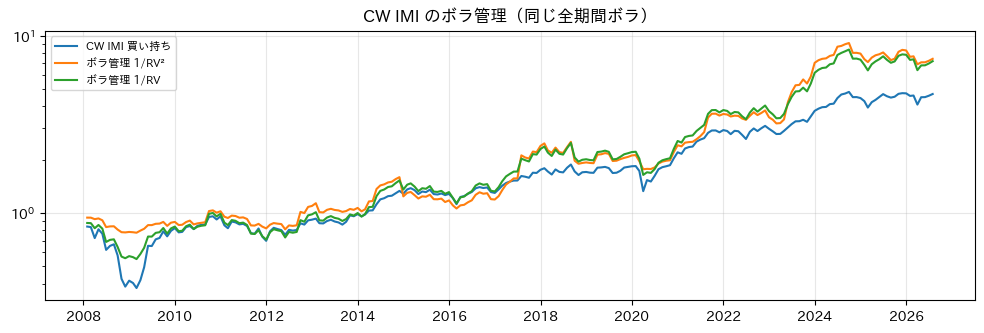

In [12]:
def vol_managed(c, power):
    f = mi_full[c]
    w = 1 / RV[c].shift(1) ** power
    df = pd.DataFrame({"f": f, "w": w}).loc[START:END].dropna()
    fs = df["w"] * df["f"]
    cst = df["f"].std() / fs.std()
    fs = fs * cst
    b, t, _, _ = nw_ols(fs, with_const(df["f"]))
    out = {
        "α 年率": b[0] * 12,
        "α t": t[0],
        "β": b[1],
        "SR 買い持ち": sharpe(df["f"]),
        "SR 管理": sharpe(fs),
    }
    for name, part in zip(("IS", "OOS"), split(pd.DataFrame({"fs": fs, "f": df["f"]}))):
        bb, tt, _, _ = nw_ols(part["fs"], with_const(part["f"]))
        out[f"α t {name}"] = tt[0]
    lev = df["w"] * cst
    out["倍率 中央"] = lev.median()
    out["倍率 最大"] = lev.max()
    return out, fs


rows = {}
vm_series = {}
for c in RV.columns:
    for power, lab in ((2, "1/RV²"), (1, "1/RV")):
        out, fs = vol_managed(c, power)
        rows[(c, lab)] = out
        vm_series[(c, lab)] = fs
print("ボラ管理（前月の実現ボラでスケール、月次 drtn）")
display(pd.DataFrame(rows).T.round(3))

rows = {}
for c in ("cw_imi", "ew_imi", "ew_small"):
    df = pd.DataFrame({"y": mi_full[c], "rv": RV[c].shift(1)}).loc[START:END].dropna()
    b, t, r2, n = nw_ols(df["y"], with_const(df["rv"]))
    q = pd.qcut(df["rv"], 3, labels=["低", "中", "高"])
    rows[c] = {"b": b[1], "t": t[1], "R²": r2} | {
        f"翌月 {k}ボラ": v for k, v in df.groupby(q, observed=True)["y"].mean().items()
    }
print("前月の実現ボラ → 当月のリターン（三分位は全期間の分位で、記述用）")
display(pd.DataFrame(rows).T.round(4))

fig, ax = plt.subplots(figsize=(12, 3.5))
f = mi["cw_imi"]
ax.plot((1 + f).cumprod(), label="CW IMI 買い持ち")
ax.plot((1 + vm_series[("cw_imi", "1/RV²")]).cumprod(), label="ボラ管理 1/RV²")
ax.plot((1 + vm_series[("cw_imi", "1/RV")]).cumprod(), label="ボラ管理 1/RV")
ax.set_yscale("log")
ax.legend(fontsize=8)
ax.set_title("CW IMI のボラ管理（同じ全期間ボラ）")
plt.show()

## 4. 季節性

すべて結果を見る前に仮説を置いた。並べる検定が多いので、1 つの |t| > 2 は偶然でも出る（20 本に 1 本）。IS / OOS の両方で同符号のものを重視する。

| 効果 | 仮説 |
| --- | --- |
| 月（3 月 / 4 月） | インドの会計年度は 4 月〜3 月。3 月に損失銘柄の節税売り（個人・国内）→ 4 月に反発。小型・EW−CW・負け組で強い |
| 曜日 | 特段の事前予想なし（米国の月曜効果の有無の確認） |
| 月替わり（最終営業日 + 最初 3 営業日） | 給与・SIP（積立投信）の資金流入が月初に集中 → 月替わりが高い |
| F&O 満期 | 満期日はポジション解消でボラが上がり、満期翌日（新しい限月）に反転。満期は 2025-08 まで月末木曜、2025-09 から月末火曜（休日は前営業日） |
| 祝日前 | 祝日前は高い（世界的に観察される） |
| 予算発表日 | 平均の方向は無いが、ボラが高い |
| 総選挙の結果日 | 事例（4 件）として記述 |
| ディワリ（ムフラート取引） | 縁起の良い買い → 前後で上昇。週末の場合は翌営業日に反映 |

さらに「3 月の節税売り」をクロスセクションで直接見る: 月末 $t$ に過去 12 か月リターンで 5 分位に分け、月 $t+1$ の負け組 − 勝ち組（等ウェイト）を
カレンダー月ごとに平均する。3 月末の形成（= 会計年度のリターン）で 4 月に負け組が勝てば、節税売りの反動と整合する。

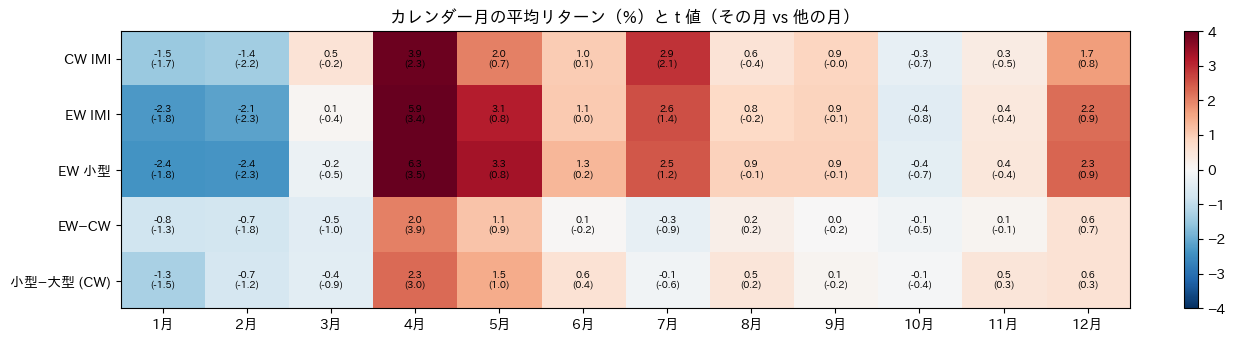

差(%)     t  t IS  t OOS
CW IMI     3月  -0.38 -0.19  0.99  -1.01
           4月   3.31  2.26  1.21   2.14
           10月 -1.31 -0.72 -0.45  -0.83
           11月 -0.62 -0.48 -1.43   1.53
EW IMI     3月  -1.03 -0.42  0.83  -1.13
           4月   5.36  3.36  2.29   2.48
           10月 -1.60 -0.75 -0.45  -1.28
           11月 -0.67 -0.42 -1.29   1.19
EW 小型      3月  -1.41 -0.54  0.71  -1.17
           4月   5.77  3.50  2.50   2.46
           10月 -1.59 -0.72 -0.43  -1.32
           11月 -0.68 -0.42 -1.18   1.08
EW−CW      3月  -0.65 -1.00 -0.07  -1.30
           4月   2.05  3.89  4.13   1.93
           10月 -0.30 -0.48 -0.33  -0.39
           11月 -0.05 -0.09 -0.33   0.24
小型−大型 (CW) 3月  -0.78 -0.90 -0.13  -1.02
           4月   2.15  2.96  3.69   1.21
           10月 -0.38 -0.44 -0.40  -0.20
           11月  0.23  0.29  0.16   0.27

In [13]:
mseries = pd.DataFrame(
    {
        "CW IMI": mi["cw_imi"],
        "EW IMI": mi["ew_imi"],
        "EW 小型": mi["ew_small"],
        "EW−CW": mi["ew_cw"],
        "小型−大型 (CW)": mi["cw_small"] - mi["cw_large"],
    }
)
month = mseries.index.month
mean_tbl = mseries.groupby(month).mean() * 100
t_tbl = pd.DataFrame(
    {c: {m: dummy_t(mseries[c], month == m)[1] for m in range(1, 13)} for c in mseries}
)
fig, ax = plt.subplots(figsize=(14, 3.6))
im = ax.imshow(mean_tbl.T.to_numpy(), cmap="RdBu_r", vmin=-4, vmax=4, aspect="auto")
ax.set_xticks(range(12), [f"{m}月" for m in range(1, 13)])
ax.set_yticks(range(mseries.shape[1]), mseries.columns)
for i, c in enumerate(mseries.columns):
    for j in range(12):
        ax.text(
            j,
            i,
            f"{mean_tbl.iat[j, i]:.1f}\n({t_tbl.iat[j, i]:.1f})",
            ha="center",
            va="center",
            fontsize=7,
        )
ax.grid(False)
plt.colorbar(im, ax=ax, fraction=0.02)
ax.set_title("カレンダー月の平均リターン（%）と t 値（その月 vs 他の月）")
plt.show()

rows = {}
for c in mseries:
    for m in (3, 4, 10, 11):
        a, b = split(mseries[c])
        rows[(c, f"{m}月")] = {
            "差(%)": dummy_t(mseries[c], month == m)[0] * 100,
            "t": dummy_t(mseries[c], month == m)[1],
            "t IS": dummy_t(a, a.index.month == m)[1],
            "t OOS": dummy_t(b, b.index.month == m)[1],
        }
display(pd.DataFrame(rows).T.round(2))

In [14]:
drtn = panel.monthly["drtn"].loc[:END]
cap_m = panel.monthly["cap"].loc[:END]
past12 = np.log1p(drtn).rolling(12, min_periods=10).sum().where(cap_m.notna())
pct = past12.rank(axis=1, pct=True)
nxt = drtn.shift(-1)
loser = nxt.where(pct <= 0.2).mean(axis=1)
winner = nxt.where(pct > 0.8).mean(axis=1)
ew_all = nxt.where(pct.notna()).mean(axis=1)
lw = pd.DataFrame(
    {
        "負け組 − 勝ち組": loser - winner,
        "負け組 − EW": loser - ew_all,
        "勝ち組 − EW": winner - ew_all,
    }
)
lw.index = lw.index + pd.offsets.MonthEnd(1)  # リターンの月で表示
lw = lw.loc[START:END].dropna()
mo = lw.index.month
tbl = lw.groupby(mo).mean() * 100
tt = pd.DataFrame(
    {c: {m: dummy_t(lw[c], mo == m)[1] for m in range(1, 13)} for c in lw}
)
out = pd.concat({"平均(%)": tbl, "t": tt}, axis=1)
print("過去 12 か月リターンの 5 分位（形成は前月末）: リターンの月ごとの平均")
display(out.round(2))
a, b = split(lw["負け組 − 勝ち組"])
print(
    f"4 月の 負け組−勝ち組: IS {a[a.index.month == 4].mean() * 100:.2f}%（{(a.index.month == 4).sum()} 年）, "
    f"OOS {b[b.index.month == 4].mean() * 100:.2f}%（{(b.index.month == 4).sum()} 年）"
)
print(
    "4 月の各年:",
    (lw.loc[lw.index.month == 4, "負け組 − 勝ち組"] * 100).round(1).to_dict(),
)

過去 12 か月リターンの 5 分位（形成は前月末）: リターンの月ごとの平均


平均(%)                           t                  
   負け組 − 勝ち組 負け組 − EW 勝ち組 − EW 負け組 − 勝ち組 負け組 − EW 勝ち組 − EW
1      -0.74    -0.58     0.16     -0.12    -0.28    -0.07
2      -1.40    -1.23     0.17     -0.86    -1.78    -0.09
3      -1.10    -1.06     0.04     -0.40    -0.90    -0.24
4       2.78     2.35    -0.43      2.41     3.42    -0.98
5       1.23     0.14    -1.10      0.66     0.33    -0.96
6      -0.37    -0.01     0.36      0.11     0.34     0.25
7      -2.75    -1.28     1.47     -2.48    -1.76     2.94
8      -2.54    -1.21     1.34     -1.51    -1.06     2.01
9      -0.54    -0.49     0.05     -0.02    -0.32    -0.37
10     -0.83    -0.44     0.39     -0.25    -0.20     0.30
11     -0.89    -0.43     0.46     -0.28    -0.15     0.43
12      0.88     0.69    -0.19      0.87     1.11    -0.54

4 月の 負け組−勝ち組: IS 3.58%（10 年）, OOS 1.90%（9 年）
4 月の各年: {Timestamp('2008-04-30 00:00:00'): 4.2, Timestamp('2009-04-30 00:00:00'): 22.8, Timestamp('2010-04-30 00:00:00'): 3.1, Timestamp('2011-04-30 00:00:00'): -0.1, Timestamp('2012-04-30 00:00:00'): -3.1, Timestamp('2013-04-30 00:00:00'): 6.6, Timestamp('2014-04-30 00:00:00'): 3.7, Timestamp('2015-04-30 00:00:00'): 1.7, Timestamp('2016-04-30 00:00:00'): 2.1, Timestamp('2017-04-30 00:00:00'): -5.1, Timestamp('2018-04-30 00:00:00'): -6.4, Timestamp('2019-04-30 00:00:00'): -5.4, Timestamp('2020-04-30 00:00:00'): 12.1, Timestamp('2021-04-30 00:00:00'): -6.4, Timestamp('2022-04-30 00:00:00'): 7.7, Timestamp('2023-04-30 00:00:00'): 5.4, Timestamp('2024-04-30 00:00:00'): -0.9, Timestamp('2025-04-30 00:00:00'): 4.6, Timestamp('2026-04-30 00:00:00'): 6.5}


In [15]:
dd = di[["cw_imi", "ew_imi", "cw_large", "ew_small", "ew_cw"]].copy()
days = dd.index
per = days.to_period("M")
pos = pd.Series(np.arange(len(days)), index=days)
first_rank = pos.groupby(per).rank(method="first")
last_rank = pos.groupby(per).rank(method="first", ascending=False)
nxt_day = pd.Series(days, index=days).shift(-1)
gap = pd.Series(
    [
        np.busday_count(a.date(), b.date()) - 1 if pd.notna(b) else 0
        for a, b in zip(days, nxt_day)
    ],
    index=days,
)


def expiry_dates(days):
    out = []
    for m in pd.period_range(days[0], days[-1], freq="M"):
        wd = 3 if m < pd.Period("2025-09", "M") else 1  # 木曜 / 火曜
        last = m.to_timestamp(how="end").normalize()
        d = last - pd.Timedelta(days=(last.dayofweek - wd) % 7)
        cand = days[(days <= d) & (days.to_period("M") == m)]
        if len(cand):
            out.append(cand[-1])
    return pd.DatetimeIndex(out)


exp = expiry_dates(days)
is_exp = pd.Series(days.isin(exp), index=days)
after_exp = is_exp.shift(1, fill_value=False)
exp_week = pd.Series(False, index=days)
for e in exp:
    wk_days = days[
        (days <= e)
        & (days > e - pd.Timedelta(days=7))
        & (days.isocalendar().week.to_numpy() == e.isocalendar().week)
    ]
    exp_week.loc[wk_days] = True

flags = {
    "月曜": days.dayofweek == 0,
    "金曜": days.dayofweek == 4,
    "月替わり（最終 + 最初 3 日）": ((first_rank <= 3) | (last_rank == 1)).to_numpy(),
    "祝日前": (gap > 0).to_numpy(),
    "F&O 満期日": is_exp.to_numpy(),
    "満期翌日": after_exp.to_numpy(),
    "満期週（満期日まで）": exp_week.to_numpy(),
}
rows = {}
for fname, f in flags.items():
    f = pd.Series(f, index=days)
    for c in dd:
        diff, t, n = dummy_t(dd[c], f)
        a, b = split(dd[c])
        fa, fb = split(f)
        rows[(fname, c)] = {
            "差(bp/日)": diff * 1e4,
            "t": t,
            "t IS": dummy_t(a, fa)[1],
            "t OOS": dummy_t(b, fb)[1],
            "日数": n,
        }
season_tbl = pd.DataFrame(rows).T
print("日次の季節性（その日 vs それ以外の日の平均の差）")
display(season_tbl.round(2))

dow = dd.groupby(days.dayofweek).mean() * 1e4
dow.index = ["月", "火", "水", "木", "金"]
print("曜日別の平均（bp/日）")
display(dow.round(1))
tom_share = (
    dd["cw_imi"].where(flags["月替わり（最終 + 最初 3 日）"]).sum() / dd["cw_imi"].sum()
)
print(
    f"CW IMI の累積リターン（単純和）のうち月替わり 4 日（全日数の {np.mean(flags['月替わり（最終 + 最初 3 日）']):.0%}）の割合: {tom_share:.0%}"
)
print(
    "満期日の |r| / 他の日の |r|（CW IMI）:",
    round(dd["cw_imi"].abs()[is_exp].mean() / dd["cw_imi"].abs()[~is_exp].mean(), 3),
)

日次の季節性（その日 vs それ以外の日の平均の差）


差(bp/日)     t  t IS  t OOS     日数
月曜                cw_imi      -5.88 -1.07  0.30  -2.08  922.0
                  ew_imi      -8.26 -1.54  0.59  -3.06  922.0
                  cw_large    -4.96 -0.88  0.24  -1.71  922.0
                  ew_small    -8.86 -1.64  0.63  -3.20  922.0
                  ew_cw       -2.38 -1.12  0.66  -2.77  922.0
金曜                cw_imi      -1.56 -0.33 -0.02  -0.52  905.0
                  ew_imi      -3.65 -0.85 -0.58  -0.62  905.0
                  cw_large    -0.87 -0.17  0.02  -0.33  905.0
                  ew_small    -4.26 -1.00 -0.85  -0.53  905.0
                  ew_cw       -2.09 -1.12 -1.19  -0.21  905.0
月替わり（最終 + 最初 3 日） cw_imi      17.35  3.57  2.95   2.00  892.0
                  ew_imi      29.03  5.38  4.47   3.00  892.0
                  cw_large    13.04  2.68  2.20   1.51  892.0
                  ew_small    31.34  5.61  4.68   3.12  892.0
                  ew_cw       11.68  5.70  5.08   2.88  892.0
祝日前               cw_imi      12.99  1.59  1.72   0.34  247.0
                  ew_imi      13.21  1.48  1.40   0.57  247.0
                  cw_large    13.34  1.62  1.83   0.24  247.0
                  ew_small    13.25  1.43  1.37   0.55  247.0
                  ew_cw        0.22  0.05 -0.34   0.49  247.0
F&O 満期日           cw_imi      -2.34 -0.32  0.11  -0.61  223.0
                  ew_imi      -8.60 -1.19 -1.02  -0.66  223.0
                  cw_large    -0.44 -0.06  0.44  -0.62  223.0
                  ew_small    -9.75 -1.33 -1.09  -0.78  223.0
                  ew_cw       -6.26 -1.85 -2.22  -0.14  223.0
満期翌日              cw_imi      33.51  3.54  3.10   1.78  223.0
                  ew_imi      41.86  4.77  3.82   2.86  223.0
                  cw_large    27.72  2.74  2.53   1.18  223.0
                  ew_small    42.85  4.88  3.79   3.06  223.0
                  ew_cw        8.34  2.00  0.50   2.76  223.0
満期週（満期日まで）        cw_imi      -4.81 -1.06 -0.87  -0.59  821.0
                  ew_imi     -10.91 -2.21 -2.33  -0.68  821.0
                  cw_large    -3.14 -0.67 -0.43  -0.53  821.0
                  ew_small   -12.02 -2.33 -2.47  -0.73  821.0
                  ew_cw       -6.10 -2.72 -3.20  -0.39  821.0

曜日別の平均（bp/日）


,cw_imi,ew_imi,cw_large,ew_small,ew_cw
月,-1.0,-3.0,-0.5,-3.5,-2.0
火,6.3,5.8,6.1,5.5,-0.5
水,11.5,13.6,10.1,14.3,2.1
木,-0.9,0.8,-1.2,1.2,1.7
金,2.4,0.7,2.8,0.1,-1.8


CW IMI の累積リターン（単純和）のうち月替わり 4 日（全日数の 19%）の割合: 93%
満期日の |r| / 他の日の |r|（CW IMI）: 0.892


満期翌日は月末に近く、月替わりの窓と重なることが多い。重なりを除くため、日次のダミーを同時に入れた回帰
（$r_d = a + \sum_j b_j D_{j,d}$、NW t）で各効果を見る。

In [16]:
X = pd.DataFrame(
    {k: np.asarray(v, dtype=float) for k, v in flags.items() if k != "金曜"}, index=days
)
print(
    "月替わりと満期翌日が重なる日数:",
    int((X["月替わり（最終 + 最初 3 日）"] * X["満期翌日"]).sum()),
    "/ 満期翌日",
    int(X["満期翌日"].sum()),
)
rows = {}
for c in ("cw_imi", "ew_imi", "ew_small", "ew_cw"):
    for pname, sl in (
        ("全期間", slice(None)),
        ("IS", slice(None, IS_END)),
        ("OOS", slice("2018-01-01", None)),
    ):
        b, t, r2, n = nw_ols(dd[c].loc[sl], with_const(*[X.loc[sl, k] for k in X]))
        rows[(c, pname)] = {f"{k} b": bb * 1e4 for k, bb in zip(X, b[1:])} | {
            f"{k} t": tt for k, tt in zip(X, t[1:])
        }
joint = pd.DataFrame(rows).T
print("同時回帰の係数（bp/日）")
display(joint[[c for c in joint if c.endswith(" b")]].round(1))
print("同時回帰の t 値")
display(joint[[c for c in joint if c.endswith(" t")]].round(2))

月替わりと満期翌日が重なる日数: 128 / 満期翌日 223


同時回帰の係数（bp/日）


月曜 b  月替わり（最終 + 最初 3 日） b  祝日前 b  F&O 満期日 b  満期翌日 b  満期週（満期日まで） b
cw_imi   全期間  -4.9                 13.9   11.4       -2.6    26.9           0.3
         IS    4.3                 17.3   20.5        4.4    37.8          -2.0
         OOS -15.7                 10.1    2.1      -11.7    14.8           3.4
ew_imi   全期間  -7.4                 24.8   10.8       -6.7    29.9          -2.4
         IS    6.2                 30.8   18.1       -0.0    34.2          -8.8
         OOS -23.2                 17.8    3.7      -15.2    25.0           5.7
ew_small 全期間  -8.0                 27.1   10.7       -7.5    29.7          -2.9
         IS    6.4                 33.3   17.9        0.1    31.9         -10.0
         OOS -24.9                 19.8    3.5      -17.3    27.4           6.3
ew_cw    全期間  -2.4                 10.9   -0.6       -4.0     2.9          -2.7
         IS    1.8                 13.6   -2.4       -4.5    -3.5          -6.8
         OOS  -7.5                  7.8    1.6       -3.6    10.2           2.3

同時回帰の t 値


月曜 t  月替わり（最終 + 最初 3 日） t  祝日前 t  F&O 満期日 t  満期翌日 t  満期週（満期日まで） t
cw_imi   全期間 -0.88                 2.82   1.40      -0.32    2.80          0.06
         IS   0.53                 2.24   1.64       0.36    2.65         -0.24
         OOS -2.10                 1.71   0.21      -1.13    1.18          0.52
ew_imi   全期間 -1.35                 4.50   1.22      -0.80    3.39         -0.41
         IS   0.81                 3.62   1.30      -0.00    2.80         -1.05
         OOS -3.09                 2.69   0.35      -1.32    1.99          0.71
ew_small 全期間 -1.46                 4.75   1.17      -0.88    3.39         -0.46
         IS   0.84                 3.82   1.26       0.01    2.64         -1.16
         OOS -3.25                 2.84   0.32      -1.45    2.16          0.72
ew_cw    全期間 -1.10                 5.17  -0.15      -1.04    0.68         -1.05
         IS   0.57                 4.56  -0.43      -0.80   -0.53         -1.88
         OOS -2.63                 2.61   0.29      -0.70    2.02          0.64

d-1  t d-1    d0  t d0   d+1  t d+1  [-5,-1]  t [-5,-1]  [0,+5]  t [0,+5]  |d0| / 平常の |r|    件数
予算   cw_imi  0.28   1.30 -0.43 -1.11  0.25   0.58    -0.58      -1.16   -0.18     -0.17            1.58  23.0
     ew_cw   0.05   0.40 -0.05 -0.51 -0.05  -0.39    -0.30      -1.18    0.05      0.22            0.96  23.0
ディワリ cw_imi  0.11   0.45  0.62  1.94  0.10   0.42     0.20       0.18    1.28      1.15            0.86  18.0
     ew_cw  -0.06  -0.30  0.50  9.44 -0.04  -0.30     0.08       0.28    0.33      1.29            1.32  18.0

総選挙の結果日（日付は反応した営業日）: CW 大型の日次リターン（%）


,2004,2009,2014,2019,2024
-1,-5.73,2.43,0.28,0.20,3.54
0,-11.85,18.05,0.38,-0.54,-6.62
1,9.37,-1.19,0.43,1.33,3.49


同 EW−CW（%）


,2004,2009,2014,2019,2024
0,14.77,-4.39,1.04,0.19,-0.06
1,-8.59,3.39,3.10,0.72,-0.23


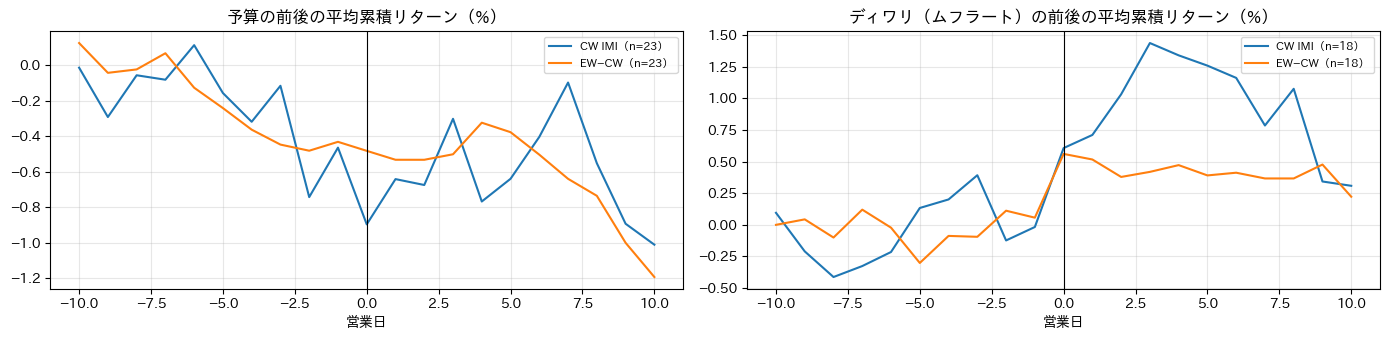

In [17]:
BUDGET = [
    "2008-02-29",
    "2009-02-16",
    "2009-07-06",
    "2010-02-26",
    "2011-02-28",
    "2012-03-16",
    "2013-02-28",
    "2014-02-17",
    "2014-07-10",
    "2015-02-28",
    "2016-02-29",
    "2017-02-01",
    "2018-02-01",
    "2019-02-01",
    "2019-07-05",
    "2020-02-01",
    "2021-02-01",
    "2022-02-01",
    "2023-02-01",
    "2024-02-01",
    "2024-07-23",
    "2025-02-01",
    "2026-02-01",
]
ELECTION = {
    "2004-05-17": "2004",
    "2009-05-18": "2009",
    "2014-05-16": "2014",
    "2019-05-23": "2019",
    "2024-06-04": "2024",
}
MUHURAT = [
    "2008-10-28",
    "2009-10-17",
    "2010-11-05",
    "2011-10-26",
    "2012-11-13",
    "2013-11-03",
    "2014-10-23",
    "2015-11-11",
    "2016-10-30",
    "2017-10-19",
    "2018-11-07",
    "2019-10-27",
    "2020-11-14",
    "2021-11-04",
    "2022-10-24",
    "2023-11-12",
    "2024-11-01",
    "2025-10-21",
]
dall = di_full.copy()
dall["ew_cw"] = dall["ew_imi"] - dall["cw_imi"]


def event_paths(dates, col, window=10):
    # 発表日（週末なら翌営業日）を 0 とした累積リターンの経路
    idx = dall.index
    paths = {}
    for d in dates:
        i = idx.searchsorted(pd.Timestamp(d))
        if i - window < 0 or i + window >= len(idx):
            continue
        seg = dall[col].iloc[i - window : i + window + 1].to_numpy()
        paths[idx[i].date()] = pd.Series(seg, index=range(-window, window + 1))
    return pd.DataFrame(paths)


def event_summary(dates, col):
    p = event_paths(dates, col)
    typical = dall[col].loc[START:].abs().mean()
    out = {}
    for lab, rng in (
        ("d-1", [-1]),
        ("d0", [0]),
        ("d+1", [1]),
        ("[-5,-1]", range(-5, 0)),
        ("[0,+5]", range(0, 6)),
    ):
        x = p.loc[list(rng)].sum()
        out[lab] = x.mean() * 100
        out[f"t {lab}"] = x.mean() / (x.std() / np.sqrt(len(x)))
    out["|d0| / 平常の |r|"] = p.loc[0].abs().mean() / typical
    out["件数"] = p.shape[1]
    return out


rows = {}
for name, dates in (("予算", BUDGET), ("ディワリ", MUHURAT)):
    for col in ("cw_imi", "ew_cw"):
        rows[(name, col)] = event_summary(dates, col)
display(pd.DataFrame(rows).T.round(2))

el = (
    pd.DataFrame(
        {
            ELECTION[str(k)]: v
            for k, v in event_paths(ELECTION.keys(), "cw_large").items()
        }
    ).loc[[-1, 0, 1]]
    * 100
)
el_s = (
    pd.DataFrame(
        {ELECTION[str(k)]: v for k, v in event_paths(ELECTION.keys(), "ew_cw").items()}
    ).loc[[0, 1]]
    * 100
)
print("総選挙の結果日（日付は反応した営業日）: CW 大型の日次リターン（%）")
display(el.round(2))
print("同 EW−CW（%）")
display(el_s.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
for ax, (name, dates) in zip(
    axes, (("予算", BUDGET), ("ディワリ（ムフラート）", MUHURAT))
):
    for col, lab in (("cw_imi", "CW IMI"), ("ew_cw", "EW−CW")):
        p = event_paths(dates, col)
        ax.plot(p.mean(axis=1).cumsum() * 100, label=f"{lab}（n={p.shape[1]}）")
    ax.axvline(0, color="k", linewidth=0.8)
    ax.set_title(f"{name}の前後の平均累積リターン（%）")
    ax.set_xlabel("営業日")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. オーバーナイト vs 日中

**仮説**: 米国（Lou–Polk–Skouras 2019 など）のように、指数のリターンはオーバーナイトで稼ぎ、日中は小さい。サイズで違う。

- 個別株のオーバーナイト $r^{on} = O_t / C_{t-1} - 1$、日中 $r^{id} = C_t / O_t - 1$（`turnover_org` の調整済み価格）。
  CW（前月末の時価総額、月中のドリフトなし = 近似）と EW で集計する。
- データの注意: 2010 年 10 月以前は NSE のプレオープン（板寄せ）が無く、始値は最初の約定値。流動性の低い銘柄では始値 = 前日終値になりやすい。
  始値が前日終値と一致する割合を診断に出す。

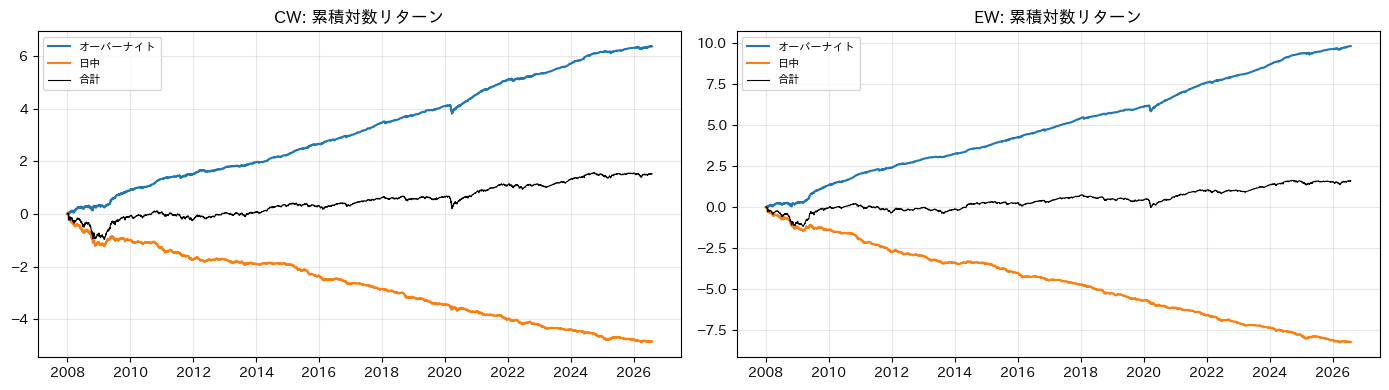

オーバーナイト / 日中の年率（%、単純平均 × 252）


,2008–12,2013–17,2018–21,2022–26,全期間,t
CW on,36.9,35.5,42.4,28.7,35.7,12.9
CW id,-32.2,-22.2,-28.2,-18.0,-25.1,-6.8
EW on,61.4,50.9,56.3,49.9,54.6,17.2
EW id,-57.6,-34.1,-46.3,-35.4,-43.4,-9.8
EW 大型 on,37.8,34.6,40.3,31.0,35.8,13.0
EW 大型 id,-34.2,-23.9,-28.1,-18.1,-26.2,-6.6
EW 中型 on,39.0,43.2,39.7,39.0,40.3,13.6
EW 中型 id,-26.4,-25.8,-31.6,-24.9,-27.0,-5.9
EW 小型 on,67.9,55.6,62.2,54.5,60.1,18.0
EW 小型 id,-65.0,-37.5,-51.8,-39.8,-48.5,-10.4


始値 = 前日終値の割合（構成銘柄、年平均）


date,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
割合,0.031,0.033,0.045,0.047,0.05,0.06,0.05,0.046,0.048,0.053,0.053,0.066,0.052,0.055,0.062,0.088,0.082,0.106,0.094


CW: 翌日のオーバーナイトと当日の日中の相関（日中の反転）: 0.146 / 当日オーバーナイトと当日日中: -0.007


In [18]:
on = panel.daily["ret_on"].loc[START:END]
idr = panel.daily["ret_id"].loc[START:END]
mem = panel.member_daily("cap").loc[START:END].reindex(columns=on.columns)
size_d = panel.member_daily("size").loc[START:END].reindex(columns=on.columns)
valid = mem.notna() & on.notna() & idr.notna()


def wavg(x, w):
    w = w.where(valid)
    return (x * w).sum(axis=1) / w.sum(axis=1)


ones = valid.astype(float)
oi = pd.DataFrame(
    {
        "CW on": wavg(on, mem),
        "CW id": wavg(idr, mem),
        "EW on": wavg(on, ones),
        "EW id": wavg(idr, ones),
    }
)
for code_, name in ((1, "大型"), (2, "中型"), (3, "小型")):
    m = (size_d == code_).astype(float)
    oi[f"EW {name} on"] = wavg(on, m)
    oi[f"EW {name} id"] = wavg(idr, m)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, pre in zip(axes, ("CW", "EW")):
    ax.plot(np.log1p(oi[f"{pre} on"]).cumsum(), label="オーバーナイト")
    ax.plot(np.log1p(oi[f"{pre} id"]).cumsum(), label="日中")
    ax.plot(
        np.log1p(oi[f"{pre} on"]).cumsum() + np.log1p(oi[f"{pre} id"]).cumsum(),
        label="合計",
        color="k",
        linewidth=0.8,
    )
    ax.set_title(f"{pre}: 累積対数リターン")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

periods = {
    "2008–12": ("2008", "2012"),
    "2013–17": ("2013", "2017"),
    "2018–21": ("2018", "2021"),
    "2022–26": ("2022", "2026"),
}
rows = {}
for col in oi.columns:
    row = {}
    for pname, (a, b) in periods.items():
        x = oi[col].loc[a:b]
        row[pname] = x.mean() * 252 * 100
    m, t = nw_mean(oi[col])
    row["全期間"] = m * 252 * 100
    row["t"] = t
    rows[col] = row
print("オーバーナイト / 日中の年率（%、単純平均 × 252）")
display(pd.DataFrame(rows).T.round(1))

stale = ((on == 0) & valid).sum(axis=1) / valid.sum(axis=1)
print("始値 = 前日終値の割合（構成銘柄、年平均）")
display(stale.groupby(stale.index.year).mean().round(3).to_frame("割合").T)
print(
    "CW: 翌日のオーバーナイトと当日の日中の相関（日中の反転）:",
    round(oi["CW id"].corr(oi["CW on"].shift(-1)), 3),
    "/ 当日オーバーナイトと当日日中:",
    round(oi["CW on"].corr(oi["CW id"]), 3),
)

## 6. 為替（USD/INR）

**仮説**: INR 安（USD/INR 上昇）は FPI の売りと同時に起きるので、株価と負の同時相関。INR 安が翌月の株価を予測する力は弱い
（あるとすれば、INR 安で割安になった大型株への FPI の買い戻し → 正）。

- `data/fx.csv` の月次レート（1 USD あたり INR、月末値として扱う）。$\Delta fx_t = \ln(fx_t / fx_{t-1})$、正 = INR 安。
- 当月の相関と、$\Delta fx_t$（1 か月・3 か月）で月 $t+1$ の INR 建て `drtn` 指数を予測する回帰。

USD/INR の変化と株式（INR 建て、月次）


,同時相関,予測 b 1m,t 1m,t IS 1m,t OOS 1m,予測 b 3m,t 3m,t IS 3m,t OOS 3m
CW IMI,-0.582,-0.239,-0.835,-1.091,0.639,-0.060,-0.483,-0.774,0.777
CW 大型,-0.573,-0.145,-0.524,-0.831,0.959,-0.039,-0.326,-0.615,0.931
EW 小型,-0.555,-0.629,-1.844,-2.038,0.026,-0.159,-0.978,-1.311,0.492
EW−CW,-0.345,-0.294,-3.919,-4.164,-0.856,-0.068,-1.301,-1.581,0.146


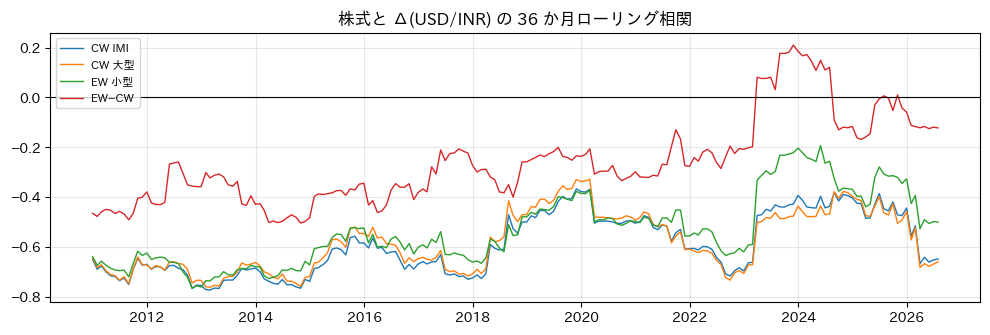

USD/INR の年率変化（INR の減価）: 4.76 %


In [19]:
fx = pd.read_csv("../../data/fx.csv")
fx.index = pd.to_datetime(
    fx["yyyymm"].astype(str), format="%Y%m"
) + pd.offsets.MonthEnd(0)
dfx = np.log(fx["rate"]).diff()
dfx3 = np.log(fx["rate"]).diff(3)
cols = {
    "cw_imi": "CW IMI",
    "cw_large": "CW 大型",
    "ew_small": "EW 小型",
    "ew_cw": "EW−CW",
}
rows = {}
for c, lab in cols.items():
    y = mi[c]
    row = {"同時相関": y.corr(dfx.reindex(y.index))}
    for nm, x in (("1m", dfx), ("3m", dfx3)):
        df = pd.DataFrame({"y": y, "x": x.shift(1)}).dropna()
        b, t, r2, _ = nw_ols(df["y"], with_const(df["x"]))
        a, bb = split(df)
        row[f"予測 b {nm}"] = b[1]
        row[f"t {nm}"] = t[1]
        row[f"t IS {nm}"] = nw_ols(a["y"], with_const(a["x"]))[1][1]
        row[f"t OOS {nm}"] = nw_ols(bb["y"], with_const(bb["x"]))[1][1]
    rows[lab] = row
print("USD/INR の変化と株式（INR 建て、月次）")
display(pd.DataFrame(rows).T.round(3))

fig, ax = plt.subplots(figsize=(12, 3.5))
for c, lab in cols.items():
    ax.plot(mi[c].rolling(36).corr(dfx.reindex(mi.index)), label=lab, linewidth=1)
ax.axhline(0, color="k", linewidth=0.8)
ax.set_title("株式と Δ(USD/INR) の 36 か月ローリング相関")
ax.legend(fontsize=8)
plt.show()
print(
    "USD/INR の年率変化（INR の減価）:",
    round(dfx.loc[START:END].mean() * 12 * 100, 2),
    "%",
)

## 所見

**結論: 指数レベルのタイミング（時系列モメンタム、ボラ管理、為替）は頑健な上乗せにならない。はっきり出たのは、(a) 等ウェイト・小型の短期の正の自己相関、
(b) カレンダー（月替わり、F&O 満期翌日、4 月の負け組・小型の反発、ムフラート）、(c) オーバーナイトで上がり日中で下がる大きな分離、の 3 つ。
これらは市場タイミングではなく、クロスセクションの運用（売買の日取り、季節で重みを変えるモメンタム、銘柄レベルのオーバーナイト / 日中シグナル）に組み込む形で使える。**

1. **短期の自己相関は小型・等ウェイトに集中**: 日次ラグ 1 は EW IMI 0.159（t 7.7）、EW 小型 0.186（t 9.2）、EW−CW 0.150（t 6.9）に対し、
   CW IMI 0.051（t 2.0）、CW 大型 0.026（t 0.9）。分散比 VR(20) は EW 小型 1.88（z 7.1）、EW IMI 1.76（z 6.0）、CW IMI 1.19（z 1.4）。
   セクターでは資本財 0.125、一般消費財 0.090、金融 0.073 が正で、IT・生活必需品・エネルギー・通信はほぼ 0。
   2018 年以降は CW・大型で消え（OOS: CW −0.026、大型 −0.065）、EW・小型では弱まりながら残る（OOS 0.102 / 0.131、t 3.4 / 4.8）。
   週次はラグ 2 だけ全指数で正（0.12〜0.17、t 2.2〜3.3）。月次は有意でない。
   注意: NSE の終値は最後の 30 分の VWAP なので、終値どうしの日次リターンには機械的な正の自己相関が少し入る。ただし CW 大型がほぼ 0 なので主因ではない。
2. **指数の時系列モメンタムは無い**: 12 か月の符号は CW IMI で t −0.8（OOS −2.4）、6 か月も OOS −2.4 で、2018 年以降はむしろ反転。
   最もましな 3 か月でも CW t 1.3、EW 小型 t 2.2 で IS / OOS がそろわない（ロング / フラットのシャープ 0.67 vs 買い持ち 0.50、現金 0%）。
   セクター TSMOM は絶対で年 5.4%（k=3、t 1.5）、相対（セクター − 市場）で年 1% 前後（t ≈ 1）。
3. **ボラは予測できるが、リターンは予測できない**: |r| の自己相関は 60 日先まで正。月次の log 実現ボラは HAR で R² 0.49（2013 年以降の OOS R² 0.44）。
   個別株の平均レンジボラ（Parkinson）を加えると t 3.8 で効き、HAR の項を置き換える（OOS R² 0.47）。指数ボラは平均的な個別株ボラの 0.55 倍。
   レバレッジ効果は日次で明確（corr(r_t, |r_{t+1..5}|) ≈ −0.11、逆向きの k<0 は ≈ 0）。一方、前月の実現ボラは翌月のリターンを予測しない（CW t 0.5）。
   ボラ管理（1/RV²）はシャープ 0.50 → 0.61 だが、アルファは年 6.3%（t 1.5、OOS t 0.6）で有意でなく、倍率は最大 6 倍になる。
4. **季節性**（日次は同時回帰で重なりを除いた値）
   - **月替わり**（最終営業日 + 最初 3 営業日、全日数の 19%）: CW IMI の累積の 93% をこの 4 日で稼ぐ。同時回帰で CW +13.9bp/日（t 2.8）、
     EW +24.8bp（t 4.5）、**EW−CW +10.9bp（t 5.2、IS 4.6 / OOS 2.6）**。小型ほど強く、月初の SIP（積立投信）資金と整合。
   - **F&O 満期翌日**: CW +26.9bp（t 2.8）、EW +29.9bp（t 3.4）。223 回中 128 回は月替わりと重なるが、同時回帰でも残る。OOS は弱まる（CW t 1.2、EW t 2.0）。
     満期日そのものは平均もボラも平常並み（|r| は平常の 0.89 倍）。市場全体の効果で、EW−CW には出ない（IS −3.5bp）。
   - **4 月**: EW IMI は他の月より +5.4%（t 3.4、IS 2.3 / OOS 2.5）、EW−CW +2.05%（t 3.9、IS 4.1 / OOS 1.9）。
     クロスセクションでも、過去 12 か月の負け組 − 勝ち組（5 分位、等ウェイト）は 4 月だけ +2.78%（t 2.4）、負け組 − EW +2.35%（t 3.4）。
     IS 3.6% / OOS 1.9% で、19 年中 12 年が正。会計年度末（3 月）の節税売りの反動と整合する。ただし 3 月の負け組の負け（−1.06%、t −0.9）ははっきりしない。
   - 7〜8 月は勝ち組 − EW が +1.47% / +1.34%（t 2.9 / 2.0）で、事前の仮説に無い結果（第 1 四半期決算の時期）。多重検定を考えると候補扱い。
   - **ディワリ（ムフラート取引、週末なら翌営業日）**: EW−CW +0.50%（t 9.4）で **18 年すべて正**（+0.06〜+0.93%）。CW IMI は +0.62%（t 1.9）。
   - 月曜は IS で正、OOS で負（EW t −3.1）と符号が逆転しており頑健でない。祝日前 +11bp（t 1.4）、予算発表日は方向なし（ボラは平常の 1.6 倍）。
   - 総選挙: 2009 年 +18.1%（CW 大型）、2004 年 −11.9%、2024 年 −6.6%。事例として記録するのみ。
5. **オーバーナイトで上がり、日中で下がる**: CW のオーバーナイト年 +35.7%（t 12.9）、日中 −25.1%（t −6.8）。EW は +54.6% / −43.4%、EW 小型は +60.1% / −48.5%。
   4 つの期間・すべての規模で同じ形。オーバーナイトは 69% の日で正（中央値 +18bp）、上位 1% の日の寄与は 22% にとどまり、一部の日だけの現象ではない。
   当日の日中と翌日のオーバーナイトの相関は +0.15（反転ではなく継続。VWAP 終値の遅れと整合）。
   注意: 始値はプレオープンの板寄せ価格、終値は最後の 30 分の VWAP で、どちらも「最終約定」ではない。始値 = 前日終値の銘柄は 3%（2008）→ 10%（2025）に増えた。
6. **為替**: USD/INR の変化と CW IMI の同時相関は −0.58（INR 安 = 株安）。INR 安が翌月の EW−CW を下げる関係は t −3.9 だが、IS（−4.2）だけで OOS は −0.9。
   INR の減価は年 4.8%。

**含意（時系列の要素をクロスセクションにどう入れるか）**

- **市場タイミングにはコストをかけない**: TSMOM・ボラ管理・為替のどれも OOS で残らない。ベータは一定に保ち、時系列の情報は「いつ・何を売買するか」と
  「どのファクターに重みを置くか」に使う。
- **売買の日取り**: 月替わりと満期翌日に市場、特に小型が上がる。BM 比で中小型を多く持つロングオンリーでは、買いは月末の前、売りは月初の窓に寄せるだけで、
  シグナルを変えずに執行コストを減らせる可能性がある。バックテストの「月末終値でリバランス」という仮定自体が、この窓の位置に影響される点にも注意。
- **季節で重みを変えるモメンタム**: 4 月は 12 か月の負け組が反発するので、3 月末のリバランスでモメンタム（`sleeve_b`）の重みを下げる、または負け組を売らない。
  インドの課税年度も 4〜3 月なので、ポートフォリオ側で 3 月に損失を実現して 4 月に買い戻す運用と組み合わせられるかは、税制の確認が要る。
- **小型の遅い価格調整**: EW・小型の正の自己相関は、大型の情報が小型に遅れて伝わるリードラグと整合する（分担 04 の銘柄レベルの検証に回す）。
  業種モメンタム（1 か月で続伸）の既存結果とも同じ方向。
- **ボラの予測はリスク側で使う**: 個別株の平均レンジボラは指数ボラの予測を改善する。TE 目標やリスクモデルの調整に使える（リターン予測には使えない）。

**次の候補（アイディア）**

1. **銘柄レベルのオーバーナイト / 日中シグナル**（根拠: 強い。core 123 本と重複なし）: 過去 1〜12 か月のオーバーナイトと日中のリターンを分けた
   モメンタム / リバーサル（Lou–Polk–Skouras の「綱引き」）。指数レベルの分離がこれだけ大きいので、銘柄間の差にも情報がある可能性が高い。
2. **4 月の節税売り反動の季節オーバーレイ**（根拠: 中。IS / OOS とも正だが OOS は弱い。既存研究と重複なし）: `comp_ew` と `sleeve_b` の Q5−Q1 をカレンダー月で分解し、
   3 月末だけモメンタムを外す / 会計年度リターンの負け組を加点する版を検証する。7〜8 月の勝ち組の強さ（決算期）も同じ枠組みで確認する。
3. **リバランス日の最適化**（根拠: 月替わりの EW−CW は強い、満期翌日は中）: 月末の前後 ±5 営業日でリバランス日をずらしたときの、同じシグナルの成績差を見る。
   税も回転率も増えない改善。
4. **小型の遅い伝播を使った銘柄シグナル**（根拠: 強い。業種モメンタムと一部重複）: 大型・同業種のリターンに対する小型株の遅れ（ラグ付きベータ、価格遅延）。分担 04 と統合する。
5. ムフラート・予算・満期は単日で小さく、運用上は売買日の回避 / 選好程度の価値。ボラのレンジ推定は bax のリスク側の改善候補。